![Banner](../../../../Images/Banner/07_remote_sensing/09_01_banner_rs_banner.png)


# Getting Access to Remote Sensing Images

A remote sensing project starts with a file, or with a window of a file that still lives in the cloud.


## Overview

The catalogues are public. The hard part is knowing which catalogue holds which kind of image, and which GeoLattice call talks to it.

This notebook is that map. It uses **`geolattice.rsense.get_images`**, the same search and download
path as PyGIS Explorer, and shows the two other doors in the library: lazy cloud cubes
(`geolattice.rsense.access` and the one-call loaders) and a GeoTIFF you already have
(`geolattice.rsense.read`). The examples use a small area around Ithaca, New York, plus Landsat,
UAV and lidar files that ship in the GeoLattice `data/` folder.

Notebook 09_01_00 covers the physics. Notebook `09_01_03_data_discovery_and_access` goes further into
STAC items, Cloud-Optimized GeoTIFFs and data cubes. The sensor modules after that assume you
can already get the image.

If `import geolattice` fails, finish notebook `09_01_01_the_python_geospatial_environment` and come
back.


## Core concepts

### Learning objectives

1. Choose among the three GeoLattice doors: download files, open a lazy cube, or read a local raster.
2. Match an image type (optical, radar, lidar, aerial, thermal, atmospheric) to a source and a
   collection.
3. Build an area of interest from a bounding box or a vector file.
4. Search a catalogue and read the scene list before any download.
5. Write a `get_images` call that clips the bands you need, and know when the product is always
   a whole file.
6. Open a GeoTIFF that is already on disk.

> **About the live sections.** Several sections query internet services. The notebook checks
> whether it can reach them: when they are available the cells run in full; otherwise they
> print a short message. Offline, the catalogue, the area of interest and the local files
> still run. The *Download with `get_images`* section writes files only if you set `DOWNLOAD = True`.

### Data

| Source | Used for |
|---|---|
| `Data/00_shared/data_remote_sensing/Data_Ithaca/Sentinel_2/aoi.geojson` | Area of interest around Ithaca, New York |
| `Data/00_shared/vector_data/USA/NY_County_GCS.shp` | Tompkins County boundary for the MODIS clip in section 9 |
| `Data/00_shared/data_remote_sensing/UAV/` | Local UAV mosaics, opened the same way as a satellite GeoTIFF |
| `Data/00_shared/data_remote_sensing/Data_Ithaca/Lidar/` | USGS 3DEP LAZ tiles already downloaded for this area |
| Earth Search, Planetary Computer, Copernicus, USGS 3DEP (live) | Scene lists for Sentinel-2, Landsat, MODIS, HLS, NAIP, Sentinel-1, Sentinel-5P and lidar |

### Contents

1. Setup
2. Three ways GeoLattice gets an image
3. Which call for which image
4. The catalogue inside `get_images`
5. An area of interest
6. Search before you download
7. Download with `get_images`
8. Lazy cubes, without saving a file
9. Files you already have
10. Accounts
11. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [ ]:
# Setup for getting access to remote-sensing images.
#
# 1. Import Path, pandas, GeoPandas and matplotlib, plus a small HTTP helper
#    used to test whether a catalogue is reachable.
# 2. Import geolattice.rsense twice: as rs for the lower-level readers, and as gi
#    for the high-level search/download API in geolattice.rsense.get_images.
# 3. Print the package versions. Later cells add the data paths and the
#    online/offline flag.

%matplotlib inline
import warnings  # warning control
warnings.filterwarnings("ignore", category=UserWarning)  # hide routine library warnings

import importlib.util  # check whether optional packages are installed
import urllib.request  # check whether a server can be reached
from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import geopandas as gpd  # vector data
import matplotlib.pyplot as plt  # figures

import geolattice  # GeoLattice
import geolattice.rsense as rs  # GeoLattice remote sensing subpackage
from geolattice.rsense import get_images as gi  # one-call search and download of satellite images

# figure resolution and a light grid
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print(f"geolattice {geolattice.__version__} | geolattice.rsense {rs.__version__}")  # versions

geolattice 0.3.10 | geolattice.rsense 0.2.0.dev0


In [ ]:
# Locate the local files and check what this machine can reach.
#
# 1. The Ithaca AOI is a GeoJSON polygon. UAV mosaics and lidar LAZ tiles are
#    files you already have, used in the last section. outputs/images is where
#    a download would be written.
# 2. reachable() probes Earth Search. ONLINE is False when that call fails, and
#    the live searches below then skip instead of raising.
# 3. HAVE records optional packages (pystac-client, earthaccess, laspy, ...).
#    get_images itself does not need all of them; the lower-level STAC and
#    lidar cells do.

DATA = Path("../../../../Data")
AOI_FILE = DATA / "00_shared" / "data_remote_sensing" / "Data_Ithaca" / "Sentinel_2" / "aoi.geojson"  # Ithaca AOI polygon
UAV_DIR = DATA / "00_shared" / "data_remote_sensing" / "UAV"  # drone (UAV) mosaics
LIDAR_DIR = DATA / "00_shared" / "data_remote_sensing" / "Data_Ithaca" / "Lidar"  # lidar tiles
OUT = Path("outputs/images")  # where downloaded images are saved

print("AOI file:   ", AOI_FILE.exists(), AOI_FILE.name)  # is the AOI file there?
print("UAV mosaics:", len(list(UAV_DIR.glob('*.tif'))) if UAV_DIR.exists() else 0)  # number of UAV mosaics
print("Lidar tiles:", len(list(LIDAR_DIR.glob('*.laz'))) if LIDAR_DIR.exists() else 0)  # number of lidar tiles


def reachable(url, timeout=8):  # can a URL be opened within the timeout?
    try:
        urllib.request.urlopen(url, timeout=timeout)  # try to open it
        return True  # the server answered
    except Exception:
        return False  # no connection


ONLINE = reachable("https://earth-search.aws.element84.com/v1")  # is the Earth Search STAC API reachable?
HAVE = {  # which optional packages are installed
    name: importlib.util.find_spec(name) is not None
    for name in ("pystac_client", "planetary_computer", "odc", "earthaccess", "asf_search", "ee", "laspy")
}
print("Earth Search reachable:", ONLINE)  # online status
print("Optional packages:", HAVE)  # optional packages
if not ONLINE:  # offline
    # explain what still runs
    print("Running offline. Catalogue, AOI and local files still run. Live searches will be skipped.")

AOI file:    True aoi.geojson
UAV mosaics: 3
Lidar tiles: 2


Earth Search reachable: True
Optional packages: {'pystac_client': True, 'planetary_computer': True, 'odc': False, 'earthaccess': False, 'asf_search': False, 'ee': False, 'laspy': False}


## Three ways GeoLattice gets an image

Every later notebook uses one of these three doors. Pick the door from what you want at the end: a folder of files, an array you have not downloaded, or a path you already have.

| Door | When to use it | What you call | What you get |
|---|---|---|---|
| Download | You want GeoTIFFs, a band stack, a NetCDF or a LAZ on disk | `geolattice.rsense.get_images.search_images` then `get_images` | Files in a folder you choose, plus `aoi.geojson` and `request.json` |
| Lazy cube | The scene is a cloud GeoTIFF and you only need the pixels inside your area | `rs.access.stac_search` / `stac_load`, or `rs.optical.load_sentinel2` and the other loaders | An `xarray` dataset. Bytes move when you compute or plot |
| Local file | The image is already on disk, including UAV mosaics and commercial samples | `rs.read` | An `xarray` data array with coordinates and a CRS |

`get_images` is the door this notebook spends the most time on. It speaks to five catalogues:

| `source` | Catalogue | Login to search |
|---|---|---|
| `earth-search` | Earth Search on AWS (Element 84) | None |
| `planetary` | Microsoft Planetary Computer | None |
| `cdse` | Copernicus Data Space | None to search. A free CDSE account to download |
| `noaa` | NOAA Digital Coast aerial photography | None |
| `usgs` | USGS 3DEP lidar | None |

`collection` is a name from that source. `list_collections()` prints the legal names, so you do not have to remember them.


## Which call for which image

The table is the working map. Resolutions are the usual product resolution for that mission. Dates in the examples are July 2024 unless the product is a snapshot (NAIP, lidar, surface water).

| Image | Typical use | GeoLattice call |
|---|---|---|
| Sentinel-2 L2A | 10 m surface reflectance, vegetation, land cover | `get_images(..., source="earth-search", collection="sentinel-2-l2a")` or `rs.optical.load_sentinel2` |
| Sentinel-2 L1C | Top-of-atmosphere reflectance | `collection="sentinel-2-l1c"` on Earth Search, or CDSE `product_type="S2MSI1C"` |
| Landsat Collection 2 Level-2 | 30 m surface reflectance and thermal | `source="planetary", collection="landsat-c2-l2"` or `rs.optical.load_landsat` |
| Landsat Level-1 | Digital numbers or top-of-atmosphere | `landsat_product="l1tp"` (or `"toa"`, `"l1gt"`) |
| MODIS vegetation indices | 250 m NDVI and EVI, 16-day | `collection="modis-13Q1-061"` |
| MODIS surface reflectance | 250 m red and near infrared, 8-day | `collection="modis-09Q1-061"` |
| MODIS LAI / GPP | Leaf area, photosynthesis | `modis-15A2H-061`, `modis-17A2H-061` |
| HLS | 30 m Landsat and Sentinel-2 on one grid | `hls2-s30`, `hls2-l30`, or `rs.optical.load_hls` (Earthdata login for the NASA copy) |
| NAIP | Sub-metre US aerial, red/green/blue/near infrared | `source="earth-search", collection="naip"` |
| NOAA coastal aerial | Natural color or color-infrared along the US coast | `source="noaa", collection="noaa-rgb8"` (also `noaa-rgbn8`, `noaa-cir8`) |
| Sentinel-1 RTC | Analysis-ready C-band backscatter | `collection="sentinel-1-rtc"` or `rs.sar.load_rtc` |
| Sentinel-1 GRD / SLC | GRD from Planetary Computer; SLC for InSAR from ASF | `sentinel-1-grd`, or `rs.access.asf_search` |
| Sentinel-3 | Ocean color, land surface temperature, fire | Planetary Computer `sentinel-3-*-l2-netcdf` collections |
| Sentinel-5P | NO₂, ozone, CO, methane and other gases | `collection="sentinel-5p-l2-netcdf", s5p_product="L2__NO2___"` |
| JRC Global Surface Water | Water occurrence and change | `collection="jrc-gsw"` |
| USGS 3DEP lidar | Point clouds (LAZ) or a streaming EPT URL | `source="usgs", collection="lidar-lpc"`, or `rs.lidar.usgs_3dep_ept` |
| UAV orthomosaic | Your own flight, or a GeoTIFF in `data/` | `rs.read`, and `rs.uav` for flight planning and OpenDroneMap |
| Commercial samples | WorldView, SkySat, Jilin under `Data/00_shared/data_remote_sensing/Commercial_images/` | `rs.read` on the GeoTIFF in the sample bundle |
| Google Earth Engine | Any Earth Engine collection | `rs.access.gee_to_xarray` after `gee_init` |

Two names for the same argument show up often. `sensor=` is another name for `collection`. `cloud=` and `max_cloud=` are the same cloud-cover limit, in percent.


## The catalogue inside `get_images`

The names above are `COLLECTIONS` in `geolattice.rsense.get_images`. The next cell builds a table from that object: every source, every collection, and the bands `get_images` downloads when you omit `bands`. An empty band list means the product is a whole file (a SAFE archive, a coastal photo, a LAZ tile, a NetCDF).


In [ ]:
# Build a table of every collection get_images knows about.
#
# list_collections() groups collection ids by catalogue (earth-search, planetary,
# cdse, noaa, usgs). For each one this loop records:
#   - the short source id and the human catalogue name
#   - the collection id and its product label
#   - the bands get_images downloads if you do not pass bands=[...]
#   - whether a login is required
# Most STAC catalogues can be searched with no account. Copernicus is the
# exception: search is public, but downloading a SAFE file needs a CDSE login.

LOGIN = {
    "earth-search": "none",
    "planetary": "none",
    "cdse": "search is public; download needs a CDSE account",
    "noaa": "none",
    "usgs": "none",
}

rows = []  # one row per collection
for source, collections in gi.list_collections().items():  # every catalogue and its collections
    for collection in collections:  # every collection
        bands = gi.default_bands(collection, source)  # its default bands
        rows.append({  # one row: catalogue, collection and bands
            "source": source,
            "catalogue": gi.SOURCE_LABELS[source],
            "collection": collection,
            "product": gi.COLLECTION_LABELS.get(collection, collection),
            "default_bands": ", ".join(bands) if bands else "(whole file)",
            "login": LOGIN[source],
        })

catalogue = pd.DataFrame(rows)  # as a table
# number of collections and catalogues
print(f"{len(catalogue)} collections across {catalogue['source'].nunique()} catalogues")
catalogue  # show the table

37 collections across 5 catalogues


,source,catalogue,collection,product,default_bands,login
0,earth-search,Earth Search (AWS),sentinel-2-l2a,Sentinel-2 L2A,"red, green, blue, nir, scl",none
1,earth-search,Earth Search (AWS),sentinel-2-l1c,Sentinel-2 L1C,"red, green, blue, nir, scl",none
2,earth-search,Earth Search (AWS),landsat-c2-l2,Landsat Collection 2,"red, green, blue, nir",none
3,earth-search,Earth Search (AWS),naip,USDA NAIP (latest),"red, green, blue, nir",none
4,planetary,Planetary Computer,sentinel-2-l2a,Sentinel-2 L2A,"red, green, blue, nir, scl",none
5,planetary,Planetary Computer,sentinel-1-rtc,Sentinel-1 RTC,"vv, vh",none
6,planetary,Planetary Computer,sentinel-1-grd,Sentinel-1 GRD,"vv, vh",none
7,planetary,Planetary Computer,landsat-c2-l2,Landsat Collection 2,"red, green, blue, nir",none
8,planetary,Planetary Computer,modis-17A2H-061,MODIS Gross Primary Productivity 8-Day,"gpp, net_photosynthesis",none
9,planetary,Planetary Computer,modis-15A2H-061,MODIS Leaf Area Index/FPAR 8-Day,"lai, fpar",none


In [ ]:
# List the exact strings you are allowed to pass for bands and product options.
#
# bands_for(collection) is the check to run before a download: a name that is
# not in this list is rejected. The enums below are the other constrained
# arguments: Sentinel-1 polarizations and modes, Landsat product levels,
# Sentinel-5P product codes, and the Copernicus product types for Sentinel-2.
# Use these strings; do not invent abbreviations.

# Band names you can pass to bands=[...]. These follow the collection, not the catalogue.
for collection in ("sentinel-2-l2a", "landsat-c2-l2", "sentinel-1-rtc", "modis-13Q1-061", "hls2-s30"):
    print(f"{collection:22} {gi.bands_for(collection)}")  # band names of this collection

print()  # blank line
print("Sentinel-1 polarizations:", list(gi.S1_POLARIZATIONS))  # Sentinel-1 polarisations
print("Sentinel-1 modes:        ", list(gi.S1_MODES))  # Sentinel-1 acquisition modes
print("Landsat products:        ", list(gi.LS_PRODUCTS))  # Landsat products
print("Sentinel-5P products:    ", ", ".join(gi.S5P_PRODUCTS))  # Sentinel-5P products
print("CDSE Sentinel-2 types:   ", ", ".join(gi.CDSE_TYPES["SENTINEL-2"]))  # CDSE Sentinel-2 product types

sentinel-2-l2a         ['blue', 'green', 'red', 'nir', 'rededge1', 'rededge2', 'rededge3', 'nir08', 'swir16', 'swir22', 'scl', 'coastal', 'visual']
landsat-c2-l2          ['blue', 'green', 'red', 'nir', 'swir16', 'swir22', 'coastal', 'lwir11', 'qa_pixel']
sentinel-1-rtc         ['vv', 'vh', 'hh', 'hv']
modis-13Q1-061         ['ndvi', 'evi', 'red', 'nir', 'blue', 'mir', 'quality', 'reliability']
hls2-s30               ['coastal', 'blue', 'green', 'red', 'rededge1', 'rededge2', 'rededge3', 'nir', 'nir08', 'swir16', 'swir22', 'fmask']

Sentinel-1 polarizations: ['VV', 'VV+VH', 'HH', 'HH+HV']
Sentinel-1 modes:         ['SM', 'IW', 'EW']
Landsat products:         ['l2', 'toa', 'l1tp', 'l1gt']
Sentinel-5P products:     L2__NO2___, L2__O3____, L2__SO2___, L2__CO____, L2__CH4___, L2__HCHO__, L2__AER_AI, L2__AER_LH, L2__CLOUD_
CDSE Sentinel-2 types:    S2MSI2A, S2MSI1C


## An area of interest

`load_aoi` accepts a bounding box or a vector dataset. The box is `(min_lon, min_lat, max_lon, max_lat)` in EPSG:4326. The vector can be a shapefile, GeoJSON, GeoPackage, GeoDataFrame or a shapely geometry. A file that carries a CRS is reprojected to longitude and latitude.

Pass `bbox` or `aoi`, not both. The same object is what `search_images` and `get_images` expect.


bbox (min_lon, min_lat, max_lon, max_lat): (-76.661224, 42.727344, -76.539001, 42.802958)
WKT: POLYGON ((-76.661224 42.727344, -76.661224 42.802958, -76.539001 42.802958, -76.539001 42.727344, -76.661224 42.727344))
from bbox: (-76.661224, 42.727344, -76.539001, 42.802958)


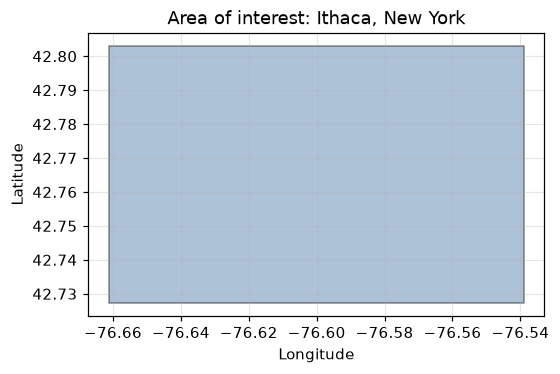

In [ ]:
# Load the Ithaca area of interest and show that a bbox is enough.
#
# gi.load_aoi accepts a GeoJSON file or a (min_lon, min_lat, max_lon, max_lat)
# tuple and returns one object with .bbox and .wkt(). Rebuilding the area from
# the four numbers shows the two forms describe the same extent. The plot is the
# polygon itself, in longitude/latitude, with equal aspect so it is not stretched.

area = gi.load_aoi(aoi=AOI_FILE)
print("bbox (min_lon, min_lat, max_lon, max_lat):", area.bbox)  # the bounding box
print("WKT:", area.wkt())  # the same area as WKT text

# The same area from the four numbers, if you do not have a file:
box_area = gi.load_aoi(bbox=area.bbox)
print("from bbox:", box_area.bbox)  # the box rebuilt from four numbers

gdf = gpd.read_file(AOI_FILE)  # the AOI polygon as a GeoDataFrame
ax = gdf.plot(facecolor="#4c78a8", edgecolor="black", alpha=0.45, figsize=(5.2, 4.2))
ax.set_title("Area of interest: Ithaca, New York")  # title
ax.set_xlabel("Longitude")  # x label
ax.set_ylabel("Latitude")  # y label
ax.set_aspect("equal")  # equal scale so the shape is not stretched
plt.tight_layout()  # arrange

## Search before you download

`search_images` returns a `SearchResult`. It holds the scene list and the original catalogue items, and it writes nothing. Read `scenes` first: each entry has an id, a time, cloud cover when the sensor reports it, and a platform.

`clearest=True` keeps the scene with the lowest cloud cover. `ids=` keeps only the scenes you name. `limit` caps the list (the default is 50).

The cells below search July 2024 over the Ithaca polygon. NAIP and lidar ignore a single month: NAIP returns the newest year that covers the area, and lidar is searched across 2018-2024 because a county is flown every few years, not every week.


In [ ]:
# Two helpers so a failed catalogue does not stop the rest of the searches.
#
# scene_frame turns a FoundScenes result into a tidy table: one row per scene,
# with the family name you passed in, the catalogue, the collection, the id,
# the date, cloud percent and the platform. An empty result becomes a single
# note row so the table still shows that the search ran.
#
# safe_search calls gi.search_images when ONLINE is True. quiet=True stops the
# progress log. Any exception is caught and printed, and an empty frame is
# returned, so one timeout does not abort the notebook.

def scene_frame(found, family):
    """One row per scene, plus a note row when the catalogue returns nothing."""
    if found is None:  # no search result
        return pd.DataFrame()  # empty table
    rows = []  # one row per scene
    for scene in found.scenes:  # every scene
        when = scene.get("datetime") or ""  # its date, if any
        rows.append({  # one row of scene properties
            "family": family,
            "source": found.source,
            "collection": found.collection,
            "scene_id": scene.get("id"),
            "date": str(when)[:10],
            "cloud_pct": None if scene.get("cloud") is None else round(float(scene.get("cloud")), 1),
            "platform": scene.get("platform") or "",
        })
    if not rows:  # nothing found
        rows.append({  # a note row instead
            "family": family,
            "source": found.source,
            "collection": found.collection,
            "scene_id": " ".join(found.notes) or "(no scenes)",
            "date": "",
            "cloud_pct": None,
            "platform": "",
        })
    return pd.DataFrame(rows)  # the table


def safe_search(family, **kwargs):  # search one image family without stopping on errors
    if not ONLINE:  # offline
        print(f"offline, skipped {family}")  # say so
        return pd.DataFrame()  # empty table
    try:
        found = gi.search_images(aoi=AOI_FILE, quiet=True, **kwargs)  # search the catalogue for the AOI
        print(f"{family:22} {found}")  # summary of the result
        return scene_frame(found, family)  # the scenes as a table
    except Exception as exc:
        print(f"{family:22} {type(exc).__name__}: {exc}")  # report the error
        return pd.DataFrame()  # empty table

In [ ]:
# Search several optical collections over Ithaca and stack the hits in one table.
#
# Every entry is (label, keyword arguments for search_images). The arguments
# that change from row to row are the catalogue (source), the collection, the
# date window, the cloud limit and how many scenes to keep (limit).
# NAIP has no date filter here: the search returns the latest aerial photos
# that intersect the AOI. Copernicus is the same Sentinel-2 archive as Earth
# Search, reached through a different catalogue.

optical = [
    ("Sentinel-2 L2A", dict(
        source="earth-search", collection="sentinel-2-l2a",
        dates=("2024-07-01", "2024-07-31"), cloud=20, limit=8)),
    ("Landsat 8/9 L2", dict(
        source="planetary", collection="landsat-c2-l2",
        dates=("2024-06-01", "2024-08-31"), cloud=40, limit=6,
        platforms="Landsat 8 and 9")),
    ("MODIS NDVI/EVI", dict(
        source="planetary", collection="modis-13Q1-061",
        dates=("2024-06-01", "2024-08-31"), limit=4)),
    ("HLS Sentinel-2", dict(
        source="planetary", collection="hls2-s30",
        dates=("2024-07-01", "2024-07-31"), cloud=30, limit=4)),
    ("NAIP", dict(
        source="earth-search", collection="naip", limit=3)),
    ("Copernicus S2 L2A", dict(
        source="cdse", collection="SENTINEL-2", product_type="S2MSI2A",
        dates=("2024-07-01", "2024-07-15"), cloud=20, limit=3)),
]

optical_table = pd.concat(  # search every optical family and stack the results
    [safe_search(family, **kwargs) for family, kwargs in optical],
    ignore_index=True,
)
optical_table  # show the table

Sentinel-2 L2A         SearchResult(earth-search/sentinel-2-l2a, 5 scenes)


Landsat 8/9 L2         SearchResult(planetary/landsat-c2-l2, 6 scenes)


MODIS NDVI/EVI         SearchResult(planetary/modis-13Q1-061, 4 scenes)


HLS Sentinel-2         SearchResult(planetary/hls2-s30, 4 scenes)


NAIP                   SearchResult(earth-search/naip, 3 scenes)


Copernicus S2 L2A      SearchResult(cdse/SENTINEL-2, 3 scenes)


,family,source,collection,scene_id,date,cloud_pct,platform
0,Sentinel-2 L2A,earth-search,sentinel-2-l2a,S2A_18TUN_20240701_1_L2A,2024-07-01,6.7,sentinel-2a
1,Sentinel-2 L2A,earth-search,sentinel-2-l2a,S2B_18TUN_20240703_0_L2A,2024-07-03,13.9,sentinel-2b
2,Sentinel-2 L2A,earth-search,sentinel-2-l2a,S2A_18TUN_20240708_0_L2A,2024-07-08,17.4,sentinel-2a
3,Sentinel-2 L2A,earth-search,sentinel-2-l2a,S2B_18TUN_20240726_0_L2A,2024-07-26,13.7,sentinel-2b
4,Sentinel-2 L2A,earth-search,sentinel-2-l2a,S2A_18TUN_20240728_0_L2A,2024-07-28,0.1,sentinel-2a
5,Landsat 8/9 L2,planetary,landsat-c2-l2,LC08_L2SP_016030_20240613_02_T1,2024-06-13,24.0,landsat-8
6,Landsat 8/9 L2,planetary,landsat-c2-l2,LC09_L2SP_015030_20240614_02_T1,2024-06-14,28.5,landsat-9
7,Landsat 8/9 L2,planetary,landsat-c2-l2,LC08_L2SP_015031_20240622_02_T1,2024-06-22,26.4,landsat-8
8,Landsat 8/9 L2,planetary,landsat-c2-l2,LC09_L2SP_016030_20240707_02_T1,2024-07-07,23.2,landsat-9
9,Landsat 8/9 L2,planetary,landsat-c2-l2,LC08_L2SP_015030_20240708_02_T1,2024-07-08,12.7,landsat-8


Sentinel-2 on Earth Search and the same sensor on Copernicus are two copies of one archive. Earth Search is the convenient place for a clipped Cloud-Optimized GeoTIFF. Copernicus is the place for the original SAFE product, and the download step needs `CDSE_USER` and `CDSE_PASSWORD`.

NAIP has no cloud field: it is aerial photography from a clear day, and `get_images` always clips the newest year that covers the box. NOAA Digital Coast is the other aerial catalogue. It covers the US coast, so an inland box such as Ithaca correctly returns no scenes. A harbor or a barrier island is the right area for `source="noaa"`.


In [ ]:
# Search the non-optical collections with the same helper.
#
# Sentinel-1 radar has no cloud cover, so the useful filters are polarization
# (VV+VH) and orbit direction (ascending vs descending). Those are separate
# searches because a time series usually keeps one orbit.
# Sentinel-5P is a short window on purpose: these are daily atmospheric
# products, and two scenes are enough to see the naming.
# USGS 3DEP lidar-lpc is a point-cloud catalog, not an image grid. The date
# window is wide because lidar is flown once every few years, not every month.

other = [
    ("Sentinel-1 ascending", dict(
        source="planetary", collection="sentinel-1-rtc",
        dates=("2024-07-01", "2024-07-31"), limit=4,
        s1_polarization="VV+VH", s1_orbit="ascending")),
    ("Sentinel-1 descending", dict(
        source="planetary", collection="sentinel-1-rtc",
        dates=("2024-07-01", "2024-07-31"), limit=4,
        s1_polarization="VV+VH", s1_orbit="descending")),
    ("Sentinel-5P NO2", dict(
        source="planetary", collection="sentinel-5p-l2-netcdf",
        dates=("2024-07-01", "2024-07-03"), limit=2,
        s5p_product="L2__NO2___")),
    ("USGS 3DEP lidar", dict(
        source="usgs", collection="lidar-lpc",
        dates=("2018-01-01", "2024-12-31"), limit=4)),
]

other_table = pd.concat(  # search the other families and stack the results
    [safe_search(family, **kwargs) for family, kwargs in other],
    ignore_index=True,
)
other_table  # show the table

Sentinel-1 ascending   SearchResult(planetary/sentinel-1-rtc, 3 scenes)


Sentinel-1 descending  SearchResult(planetary/sentinel-1-rtc, 0 scenes)


Sentinel-5P NO2        SearchResult(planetary/sentinel-5p-l2-netcdf, 2 scenes)


USGS 3DEP lidar        SearchResult(usgs/lidar-lpc, 4 scenes)


,family,source,collection,scene_id,date,cloud_pct,platform
0,Sentinel-1 ascending,planetary,sentinel-1-rtc,S1A_IW_GRDH_1SDV_20240703T230021_20240703T2300...,2024-07-03,None,SENTINEL-1A
1,Sentinel-1 ascending,planetary,sentinel-1-rtc,S1A_IW_GRDH_1SDV_20240715T230021_20240715T2300...,2024-07-15,None,SENTINEL-1A
2,Sentinel-1 ascending,planetary,sentinel-1-rtc,S1A_IW_GRDH_1SDV_20240727T230020_20240727T2300...,2024-07-27,None,SENTINEL-1A
3,Sentinel-1 descending,planetary,sentinel-1-rtc,"No scenes found for this mode, polarization, a...",,None,
4,Sentinel-5P NO2,planetary,sentinel-5p-l2-netcdf,S5P_L2_NO2____20240701T161313_20240701T175443_...,2024-07-01,None,Sentinel 5 Precursor
5,Sentinel-5P NO2,planetary,sentinel-5p-l2-netcdf,S5P_L2_NO2____20240701T170524_20240701T171024_...,2024-07-01,None,Sentinel 5 Precursor
6,USGS 3DEP lidar,usgs,lidar-lpc,USGS_LPC_NY_CayugaOswegoCounties_2018_A18_u_36...,2019-08-08,None,
7,USGS 3DEP lidar,usgs,lidar-lpc,USGS_LPC_NY_CayugaOswegoCounties_2018_A18_u_36...,2019-08-08,None,
8,USGS 3DEP lidar,usgs,lidar-lpc,USGS_LPC_NY_CayugaOswegoCounties_2018_A18_u_36...,2019-08-08,None,
9,USGS 3DEP lidar,usgs,lidar-lpc,USGS_LPC_NY_CayugaOswegoCounties_2018_A18_u_36...,2019-08-08,None,


Radar scenes have no `eo:cloud_cover`, so `clearest=True` is the wrong filter. Constrain the orbit and the polarization instead: `s1_orbit="ascending"` or `"descending"`, and `s1_polarization="VV+VH"` (or `"VV"`, `"HH"`, `"HH+HV"`). A time series of backscatter should stay on one orbit direction, because the two looks are not the same geometry. Over Ithaca in July 2024 the ascending passes intersect the polygon and the descending passes do not. An empty list means that orbit misses the polygon. Search the other direction.

Sentinel-5P is one collection and many gases. `s5p_product` selects the gas: `L2__NO2___`, `L2__O3____`, `L2__CO____`, `L2__CH4___`, and the others listed in `gi.S5P_PRODUCTS`. The file is NetCDF, so `get_images` saves the whole product rather than a map clip.

Lidar returns a tile of points. The id is the LAZ name. Tiles are large (often tens to a few hundred megabytes), so search, then pass `ids=` for the one tile you want.


## Download with `get_images`

`get_images` searches and writes files. Pass `search=` a `SearchResult` you already trust, or pass the same `aoi` and `dates` you used to search.

Arguments that change what lands on disk:

| Argument | Effect |
|---|---|
| `bands` | Asset names to keep. Defaults come from `default_bands` (red, green, blue, near infrared, and SCL for Sentinel-2) |
| `mode="clip"` | Read the area out of each Cloud-Optimized GeoTIFF. This is the default |
| `mode="full"` | Save the whole asset |
| `stack=True` | Also write `stack.tif` from red, green, blue and near infrared. Only for `mode="clip"` |
| `clearest=True` | Download the least cloudy scene only |
| `ids=` | Download these scene ids and ignore the rest |
| `limit` | How many scenes to consider |
| `workers` | Parallel downloads. The default is 4 |

Copernicus SAFE products, NOAA photos, USGS LAZ tiles and NetCDF collections are always whole files. `mode` is ignored for them. NAIP is always a clip of red, green, blue and near infrared.

Set `DOWNLOAD = True` in the next cell when you want files under `outputs/images/`. Left as `False`, the cell only prints the plan. A Sentinel-2 clip of five bands over this polygon is a few megabytes. A lidar tile is not.


In [ ]:
# Prepare download calls, and do not download unless DOWNLOAD is set to True.
#
# search_images only lists scenes. get_images searches and writes files.
# Leaving DOWNLOAD = False makes the notebook safe to re-run: it prints the
# arguments and stops. Set it to True to clip the clearest July 2024 Sentinel-2
# scene (red, green, blue, nir and the scene-classification layer) to the AOI
# and stack those bands in one file.
#
# recipes holds the same kind of call for Landsat, MODIS vegetation indices,
# HLS, NAIP, Sentinel-1, Sentinel-5P, USGS lidar, and a Copernicus SAFE zip.
# The Copernicus recipe needs CDSE_USER and CDSE_PASSWORD because it downloads
# a full product, not a clipped COG window.

DOWNLOAD = False  # True writes files under outputs/images/

# The clearest Sentinel-2 scene in July 2024, clipped to the Ithaca polygon.
sentinel2_call = dict(
    out=OUT / "sentinel2",
    aoi=AOI_FILE,
    dates=("2024-07-01", "2024-07-31"),
    source="earth-search",
    collection="sentinel-2-l2a",
    cloud=20,
    bands=["red", "green", "blue", "nir", "scl"],
    mode="clip",
    stack=True,
    clearest=True,
    limit=8,
)

# Other products. Uncomment a block inside the DOWNLOAD branch, or call get_images yourself.
recipes = {
    "landsat": dict(
        out=OUT / "landsat", aoi=AOI_FILE,
        dates=("2024-06-01", "2024-08-31"),
        source="planetary", collection="landsat-c2-l2",
        platforms="Landsat 8 and 9", cloud=40,
        bands=["red", "green", "blue", "nir", "lwir11", "qa_pixel"],
        mode="clip", clearest=True, limit=6,
    ),
    "modis_vi": dict(
        out=OUT / "modis_vi", aoi=AOI_FILE,
        dates=("2024-06-01", "2024-08-31"),
        source="planetary", collection="modis-13Q1-061",
        bands=["ndvi", "evi", "red", "nir"],
        mode="clip", limit=1,
    ),
    "hls": dict(
        out=OUT / "hls", aoi=AOI_FILE,
        dates=("2024-07-01", "2024-07-31"),
        source="planetary", collection="hls2-s30", cloud=30,
        bands=["red", "green", "blue", "nir", "fmask"],
        mode="clip", clearest=True, limit=4,
    ),
    "naip": dict(
        out=OUT / "naip", aoi=AOI_FILE,
        source="earth-search", collection="naip",
        bands=["red", "green", "blue", "nir"],
        limit=1,
    ),
    "sentinel1": dict(
        out=OUT / "sentinel1", aoi=AOI_FILE,
        dates=("2024-07-01", "2024-07-31"),
        source="planetary", collection="sentinel-1-rtc",
        s1_polarization="VV+VH", s1_orbit="ascending",
        bands=["vv", "vh"], mode="clip", limit=1,
    ),
    "sentinel5p": dict(
        out=OUT / "sentinel5p", aoi=AOI_FILE,
        dates=("2024-07-01", "2024-07-03"),
        source="planetary", collection="sentinel-5p-l2-netcdf",
        s5p_product="L2__NO2___", limit=1,
    ),
    "lidar": dict(
        out=OUT / "lidar", aoi=AOI_FILE,
        dates=("2018-01-01", "2024-12-31"),
        source="usgs", collection="lidar-lpc", limit=1,
    ),
    # Copernicus writes a full SAFE zip and needs CDSE_USER / CDSE_PASSWORD.
    "copernicus_s2": dict(
        out=OUT / "cdse_s2", aoi=AOI_FILE,
        dates=("2024-07-01", "2024-07-15"),
        source="cdse", collection="SENTINEL-2", product_type="S2MSI2A",
        cloud=20, clearest=True, limit=3,
    ),
}

print("Sentinel-2 call:")  # header
for key, value in sentinel2_call.items():  # every argument of the Sentinel-2 call
    print(f"  {key}: {value}")  # print it
print("Other recipes ready:", ", ".join(recipes))  # the other prepared recipes

if DOWNLOAD:  # only when downloading is switched on
    saved = gi.get_images(**sentinel2_call)  # search, clip and save the clearest scene
    print(saved)  # summary of the download
    print("files:", [path.name for path in saved.files])  # the saved files
else:
    print("DOWNLOAD is False. Set it to True to clip the clearest Sentinel-2 scene.")  # explain how to download
    # and how to use the other recipes
    print("Then call gi.get_images(**recipes['landsat']) or any other recipe.")

Sentinel-2 call:
  out: outputs/images/sentinel2
  aoi: ../../../../data/data_remote_sensing/Data_Ithaca/Sentinel_2/aoi.geojson
  dates: ('2024-07-01', '2024-07-31')
  source: earth-search
  collection: sentinel-2-l2a
  cloud: 20
  bands: ['red', 'green', 'blue', 'nir', 'scl']
  mode: clip
  stack: True
  clearest: True
  limit: 8
Other recipes ready: landsat, modis_vi, hls, naip, sentinel1, sentinel5p, lidar, copernicus_s2
DOWNLOAD is False. Set it to True to clip the clearest Sentinel-2 scene.
Then call gi.get_images(**recipes['landsat']) or any other recipe.


## Lazy cubes, without saving a file

`get_images` writes files you can archive, open in a GIS, or hand to someone else. When the next step is a calculation in Python, a lazy cube reads the window you need and leaves the rest in the cloud.

`rs.access.stac_search` asks a STAC catalogue (Planetary Computer, Earth Search, USGS Landsat, Copernicus, NASA LPCLOUD) and returns items. `rs.access.stac_load` turns those items into an `xarray` dataset, one variable per band, reading only the window over your area. That path needs the `rsense-access` extra:

```bash
pip install "geolattice[rsense-access]"
```

The one-call loaders wrap search, load, scale and cloud masking:

```python
s2 = rs.optical.load_sentinel2(AOI_FILE, ("2024-07-01", "2024-07-31"), max_cloud=20)
landsat = rs.optical.load_landsat(AOI_FILE, ("2024-06-01", "2024-08-31"), max_cloud=30)
modis = rs.optical.load_modis(AOI_FILE, ("2024-06-01", "2024-08-31"))
rtc = rs.sar.load_rtc(AOI_FILE, ("2024-07-01", "2024-07-31"), orbit="ascending")
```

`load_hls` reads the NASA copy of Harmonized Landsat Sentinel-2 and needs an Earthdata login. `load_sentinel2(..., catalog="earth-search")` reads the AWS copy instead of Planetary Computer.

The next cell searches Planetary Computer for Sentinel-2 when `pystac-client` is installed. It does not load pixels. Notebook 09_01_03 loads them, signs Planetary Computer URLs, and builds a cube.


In [ ]:
# The lower-level search, for when you want the STAC Items themselves.
#
# get_images hides the catalogue response. rs.access.stac_search returns the
# pystac Items, which is what you need for stac_load or a custom reader.
# This call asks Planetary Computer (not Earth Search) for up to five
# Sentinel-2 scenes. odc-stac is required to turn those items into a cube;
# without it the cell only lists ids, cloud cover and dates.
# get_images in the previous cell does not need pystac-client for every source.

if ONLINE and HAVE["pystac_client"]:
    items = rs.access.stac_search(  # search Planetary Computer for Sentinel-2 items
        "sentinel-2-l2a",
        aoi=AOI_FILE,
        dates=("2024-07-01", "2024-07-31"),
        max_cloud=20,
        catalog="planetary-computer",
        limit=5,
    )
    print(f"{len(items)} Sentinel-2 item(s) from Planetary Computer")  # number of items
    for item in items:  # every item
        props = item.properties  # its properties
        # ID, cloud cover and date
        print(f"  {item.id}  cloud={props.get('eo:cloud_cover')}  {str(props.get('datetime'))[:10]}")
    if not HAVE["odc"]:  # odc-stac missing
        # explain what is skipped
        print("odc-stac is not installed, so stac_load and the one-call loaders are not run here.")
        print('Install them with: pip install "geolattice[rsense-access]"')  # how to install it
else:
    missing = "the network" if not ONLINE else "pystac-client"  # what is missing
    print(f"STAC search skipped ({missing} is unavailable).")  # explain
    print("get_images in the previous sections does not need pystac-client.")  # get_images works without it

5 Sentinel-2 item(s) from Planetary Computer
  S2A_MSIL2A_20240728T154941_R054_T18TUN_20240728T235651  cloud=0.108902  2024-07-28
  S2B_MSIL2A_20240726T155819_R097_T18TUN_20240726T202326  cloud=13.695778  2024-07-26
  S2A_MSIL2A_20240708T154941_R054_T18TUN_20240708T224601  cloud=17.386301  2024-07-08
  S2B_MSIL2A_20240703T154819_R054_T18TUN_20240705T191444  cloud=13.898541  2024-07-03
  S2A_MSIL2A_20240701T160031_R097_T18TUN_20240702T012341  cloud=6.73191  2024-07-01
odc-stac is not installed, so stac_load and the one-call loaders are not run here.
Install them with: pip install "geolattice[rsense-access]"


## Files you already have

A path is enough once the image is local. `rs.read` opens a GeoTIFF, a Cloud-Optimized GeoTIFF, a JPEG2000 or a NetCDF subdataset as an `xarray` array. A URL works too, including `/vsicurl/` and `s3://` paths that GDAL can see.

The next cell downloads a fresh clip for Tompkins County, the county that contains Ithaca, New York. The boundary comes from `Data/00_shared/vector_data/USA/NY_County_GCS.shp`. `get_images` reads one MODIS 16-day vegetation composite (`modis-13Q1-061`) over that county and writes GeoTIFFs under `outputs/images/modis_tompkins/`. The product is 250 m and carries NDVI, red, near infrared and blue. It has no green band, so the color panel is near infrared, red and blue. Stored values are integers; multiply by 0.0001 to get NDVI and reflectance. Pixels outside the county boundary are left empty.


Tompkins County, Ithaca, NY bounds (min_lon, min_lat, max_lon, max_lat): (-76.696, 42.263, -76.238, 42.627)


1 scene(s), 0 band file(s) to fetch, 4 already present



bands: 0it [00:00, ?it/s]


bands: 0it [00:00, ?it/s]

ImageResult(planetary/modis-13Q1-061, 1 scenes, 8 files, 0 failures, out=outputs/images/modis_tompkins)
scene: MYD13Q1.A2026201.h12v04.061.2026218125341 date: 2026-07-20
clip: {'y': 129, 'x': 320} NDVI 0.09 to 0.94


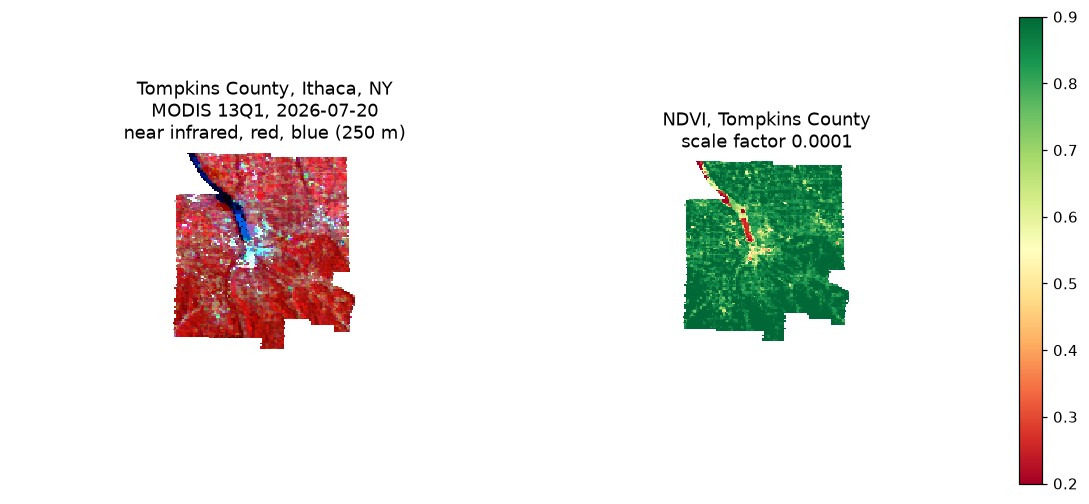

In [ ]:
# Download one MODIS vegetation scene and clip it to Tompkins County.
#
# This is the end-to-end path: a county polygon in, a north-up NDVI map out.
# Offline, it stops after printing the county bounds.
#
# 1. Keep the Tompkins County polygon (Ithaca sits inside it) and ask get_images
#    for one MOD13Q1 / MYD13Q1 scene: blue, red, NIR and NDVI, clipped to the county.
# 2. modis_band reads each GeoTIFF, drops the fill value (stored integers at or
#    below -2000) and multiplies by the product scale factor 0.0001.
# 3. county_mask clips again to the polygon, in the sinusoidal CRS the file uses.
# 4. Reproject NDVI to UTM zone 18N so the county is north-up, and warp the other
#    bands onto that same grid.
# 5. stretch() maps each band's 2nd-98th percentile onto 0-1 for display.
#    This collection has no green band, so the colour view is NIR, red, blue.
#    Pixels outside the county are painted white. The second panel is NDVI.

COUNTIES = DATA / "00_shared" / "vector_data" / "USA" / "NY_County_GCS.shp"
tompkins = gpd.read_file(COUNTIES)  # all New York counties
tompkins = tompkins.loc[tompkins["COUNTY"] == "Tompkins County"].copy()  # keep Tompkins County
print(  # its bounds
    "Tompkins County, Ithaca, NY bounds (min_lon, min_lat, max_lon, max_lat):",
    tuple(round(float(v), 3) for v in tompkins.total_bounds),
)

modis_out = OUT / "modis_tompkins"  # output folder for the MODIS clip

if not ONLINE:  # offline
    print("Offline: the MODIS clip was not downloaded.")  # say so
else:
    saved = gi.get_images(  # search, clip and save one MODIS vegetation scene
        modis_out,
        aoi=tompkins,
        dates=("2026-08-01", "2026-09-15"),
        source="planetary",
        collection="modis-13Q1-061",
        bands=["blue", "red", "nir", "ndvi"],
        mode="clip",
        limit=1,
        quiet=True,
    )
    scene = saved.scenes[0]  # the downloaded scene
    scene_dir = saved.out / scene["id"]  # its folder
    print(saved)  # summary of the download
    print("scene:", scene["id"], "date:", str(scene["datetime"])[:10])  # scene ID and date

    def modis_band(name):  # read one band, mask fill values and apply the scale factor
        """MOD13Q1 / MYD13Q1 integers, scale factor 0.0001. Fill values stay empty."""
        da = rs.read(scene_dir / f"{name}.tif").squeeze(drop=True).astype("float32")  # read as floats
        return da.where(da > -2000) * 0.0001  # fill values (<= -2000) -> NaN, then scale

    blue, red, nir, ndvi = (modis_band(name) for name in ("blue", "red", "nir", "ndvi"))  # the four bands
    tompkins_sin = tompkins.to_crs(ndvi.rio.crs)  # the county in the file's sinusoidal CRS

    def county_mask(da):  # clip a band to the county polygon
        return da.rio.clip(tompkins_sin.geometry, tompkins_sin.crs, drop=True)  # clip and drop the outside

    blue, red, nir, ndvi = (county_mask(da) for da in (blue, red, nir, ndvi))  # clip all four bands
    # The MODIS grid is sinusoidal. Put the county north-up before drawing it.
    ndvi = ndvi.rio.reproject("EPSG:32618")
    # the other bands onto the NDVI grid
    blue, red, nir = (da.rio.reproject_match(ndvi) for da in (blue, red, nir))
    # grid size and NDVI range
    print("clip:", dict(ndvi.sizes), "NDVI", round(float(ndvi.min()), 2), "to", round(float(ndvi.max()), 2))

    def stretch(values):  # 2-98 % stretch to [0, 1]
        data = np.asarray(values, dtype="float32")  # as a float array
        lo, hi = np.nanpercentile(data, (2, 98))  # percentile limits
        return np.clip((data - lo) / (hi - lo + 1e-6), 0, 1)  # stretch and clip

    # This collection has no green band. Near infrared, red and blue is the color view.
    false_color = np.dstack([stretch(nir.values), stretch(red.values), stretch(blue.values)])
    outside = ~np.isfinite(ndvi.values)  # pixels outside the county
    false_color[outside] = 1  # paint them white
    ndvi_show = np.ma.masked_where(outside, ndvi.values)  # hide them in the NDVI panel
    when = str(scene["datetime"])[:10]  # the scene date

    fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))  # two panels
    axes[0].imshow(false_color, interpolation="nearest")  # the false-colour image
    # title
    axes[0].set_title(f"Tompkins County, Ithaca, NY\nMODIS 13Q1, {when}\nnear infrared, red, blue (250 m)")
    im = axes[1].imshow(ndvi_show, cmap="RdYlGn", vmin=0.2, vmax=0.9, interpolation="nearest")  # NDVI
    axes[1].set_title("NDVI, Tompkins County\nscale factor 0.0001")  # title
    fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)  # colour bar
    for ax in axes:  # for both panels
        ax.set_axis_off()  # no axes
    plt.tight_layout()  # arrange

In [ ]:
# Inventory files that are already on disk: UAV mosaics and lidar tiles.
#
# These do not come from a STAC search. rs.read opens the first UAV GeoTIFF and
# prints its shape and CRS. Each LAZ file is listed with its size. If laspy is
# installed, rs.lidar.read_las opens the first tile far enough to count the
# points. If not, the cell prints the extra to install and does not fail.

uav_files = sorted(UAV_DIR.glob("*.tif"))
print(f"{len(uav_files)} UAV mosaic(s) in {UAV_DIR.name}/")  # number of UAV mosaics
if uav_files:  # if there are any
    uav = rs.read(uav_files[0])  # read the first one
    print(uav_files[0].name, dict(uav.sizes), "CRS", uav.rio.crs)  # its size and CRS

lidar_files = sorted(LIDAR_DIR.glob("*.laz"))  # the lidar tiles
print(f"{len(lidar_files)} LAZ tile(s) already in {LIDAR_DIR.as_posix()}")  # how many
for path in lidar_files:  # every tile
    print(f"  {path.name:60} {path.stat().st_size / 1e6:6.0f} MB")  # its name and size

if HAVE["laspy"] and lidar_files:  # laspy installed and tiles present
    cloud = rs.lidar.read_las(lidar_files[0])  # read the first tile
    print("points in first tile:", len(cloud.x))  # number of points
else:
    print('laspy is not installed, so the tiles are listed and not read.')  # laspy missing
    print('pip install "geolattice[rsense-lidar]"   # then: cloud = rs.lidar.read_las(path)')

3 UAV mosaic(s) in UAV/
multi_bwh_mc_20150212.tif {'band': 5, 'y': 703, 'x': 601} CRS None
2 LAZ tile(s) already in ../../../../data/data_remote_sensing/Data_Ithaca/Lidar
  USGS_LPC_NY_FingerLakes_2020_A20_u_3735069800.laz               116 MB
  USGS_LPC_NY_FingerLakes_2020_A20_u_3750069800.laz                86 MB
laspy is not installed, so the tiles are listed and not read.
pip install "geolattice[rsense-lidar]"   # then: cloud = rs.lidar.read_las(path)


Commercial samples (WorldView, SkySat, Jilin) live under `Data/00_shared/data_remote_sensing/Commercial_images/`. They are ordinary rasters plus a metadata file: open the GeoTIFF with `rs.read` the same way. The license in each bundle still applies.

Streaming lidar, without saving a LAZ, starts from an Entwine URL:

```python
urls = rs.lidar.usgs_3dep_ept(area.bbox)          # dataset URLs over the box
# cloud = rs.lidar.read_pdal(urls[0], bounds=...)  # needs the PDAL Python bindings
```

`get_images(..., source="usgs", collection="lidar-lpc")` is the download path. `usgs_3dep_ept` is the path that leaves the points in the cloud until you query a window.


## Accounts

Most of the calls in this notebook need no password. Keep the passwords that are required in environment variables.

| Catalogue | Variables | Needed for | Sign up |
|---|---|---|---|
| Earth Search, Planetary Computer | none | Search and Cloud-Optimized GeoTIFF reads | n/a |
| Copernicus Data Space | `CDSE_USER`, `CDSE_PASSWORD` | Downloading a SAFE product. Search is public | dataspace.copernicus.eu |
| NASA Earthdata | `EARTHDATA_USERNAME`, `EARTHDATA_PASSWORD` | ASF SLC/GRD downloads, HLS from LP DAAC, `earthdata_search` | urs.earthdata.nasa.gov |
| Google Earth Engine | a Cloud project, then `rs.access.gee_init` | `gee_to_xarray` | code.earthengine.google.com |

```python
# Copernicus download through get_images
gi.get_images(..., source="cdse", collection="SENTINEL-2", product_type="S2MSI2A",
              cdse_user="you@example.com", cdse_password="...")

# Sentinel-1 SLC for InSAR, from the Alaska Satellite Facility
results = rs.access.asf_search(aoi=AOI_FILE, dates=("2024-07-01", "2024-07-31"), product="SLC")
# rs.access.asf_download(results, "outputs/slc")   # Earthdata login
```

PyGIS Explorer uses this same `get_images` module. A search you try in the Explorer page is the search you can paste into a notebook.


## Summary and exercises


**Key ideas**

- `geolattice.rsense.get_images` searches and downloads Sentinel-2, Landsat, MODIS, HLS, NAIP,
  Sentinel-1, Sentinel-3, Sentinel-5P, NOAA coastal photos and USGS lidar.
  `list_collections()`, `bands_for()` and `default_bands()` are the names the functions accept.
- Search with `search_images` and read the scene list. Download with `get_images` once the
  list is the one you want.
- `mode="clip"` reads your area out of a Cloud-Optimized GeoTIFF. Copernicus, NOAA, lidar and
  NetCDF products are whole files.
- `rs.access` and `rs.optical.load_sentinel2`, `load_landsat`, `load_modis`, `load_hls`, plus
  `rs.sar.load_rtc`, skip the local copy and return a lazy cube.
- `rs.read` opens a GeoTIFF you already have: a Landsat subset, a UAV mosaic, or a commercial
  sample.

**Exercises**

1. Change the cloud limit on the Sentinel-2 search to 5 percent. How many July 2024 scenes
   remain over this polygon?
2. Search Landsat 5 as well as Landsat 8 and 9 (`platforms="Landsat 4-9"` is the built-in
   choice, or pass a list). Which mission appears in 2024?
3. Call `gi.default_bands` for `modis-15A2H-061` and `hls2-l30`. Which names would you pass as
   `bands` for leaf area, and which for a Landsat-like HLS scene?
4. Search Sentinel-1 twice, once ascending and once descending, and compare the scene times.
   Pick one direction before you build a backscatter series.
5. Set `DOWNLOAD = True` for the Sentinel-2 recipe only, then open `stack.tif` with `rs.read`
   and compare it with the 2015 Landsat subset.

**Next:** The optical notebooks (07_02) begin with MODIS, the daily global workhorse. The optical modules
(`07_02`) then cover Landsat and Sentinel-2. Radar, UAV and lidar each have their own folder
after that.

**References**

- USGS Landsat Collection 2, https://www.usgs.gov/landsat-missions
- Copernicus Sentinel missions, https://dataspace.copernicus.eu
- SpatioTemporal Asset Catalog, https://stacspec.org
- Microsoft Planetary Computer, https://planetarycomputer.microsoft.com
- Earth Search, https://earth-search.aws.element84.com
- USDA NAIP, https://naip-usdaonline.hub.arcgis.com
- USGS 3DEP lidar, https://www.usgs.gov/3d-elevation-program
